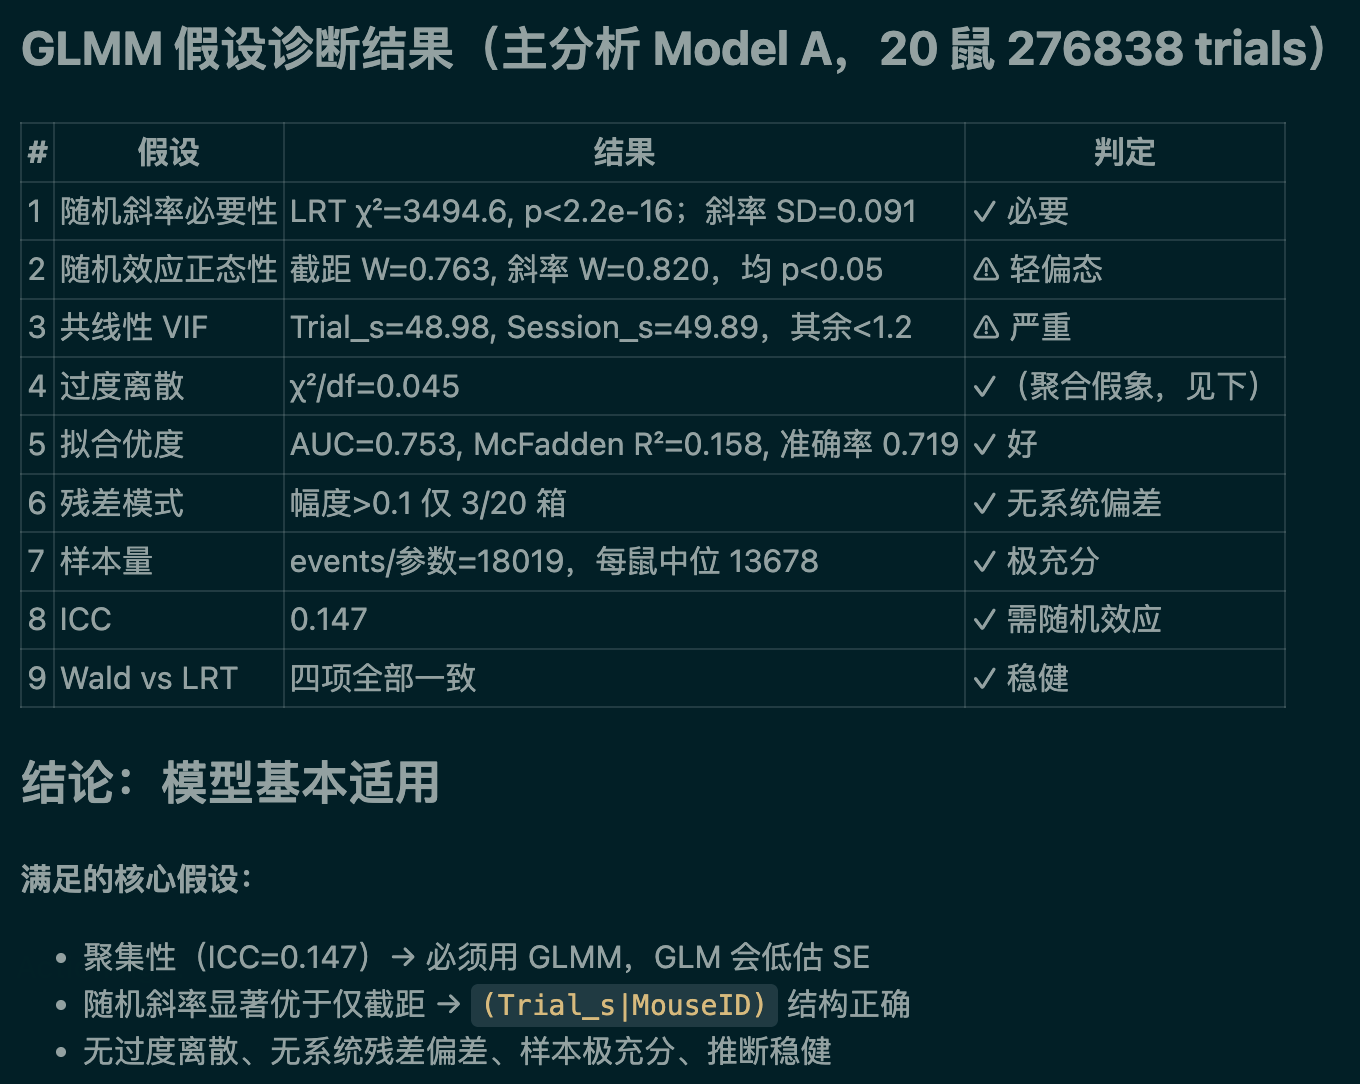

In [9]:
# ====== 手动筛选：指定想分析的特定 session（Date 起止 + MouseID + Treatment）====== 
# 参考 3-main_AnaOfdata.ipynb 的 analyzer.filter_data 接口
# 留空/None = 不限该条件。改完参数跑此格 → 写 glme_trial_data_sel.csv，下格拟合自动用
#
# ★ 主分析 = 全量：所有筛选留 None → 删旧 sel → fit 用全量 glme_trial_data.csv
#   （R 脚本内部自动剔 Ac/Am 前缀 treatment，跑 主分析20鼠 + 探索性7鼠 两套）
# ★ 子集分析：设下面任一参数 → 两套分析都基于该子集（主分析=子集剔Ac/Am，探索性=子集complete-case）
import os, pandas as pd

FULL_CSV = "/home/jyy/Documents/Beh_Ana_J/glme/glme_trial_data.csv"
SEL_CSV  = "/home/jyy/Documents/Beh_Ana_J/glme/glme_trial_data_sel.csv"

# ↓↓↓ 改这里 ↓↓↓
mouse_ids   = None           # 例 ['A07','D04'] 或 ['A07']；None=全部
treatments  = None           # 例 ['T7F','T9F']；None=全部（注意 Ac/Am 会被 R 脚本剔）
start_date  = None           # 例 20260101 (YYYYMMDD)；None=不限
end_date    = None           # 例 20260630；None=不限
# ↑↑↑ 改这里 ↑↑↑

df = pd.read_csv(FULL_CSV)
print(f"全量: {len(df)} trials, {df.MouseID.nunique()} mice, {df.Date.nunique()} sessions")

# 无任何筛选条件 → 删旧 sel（若有），下格 fit 自动回退全量 glme_trial_data.csv
no_filter = not (mouse_ids or treatments or start_date or end_date)
if no_filter:
    if os.path.exists(SEL_CSV):
        os.remove(SEL_CSV)
        print(f"\n未设筛选条件，删除旧子集 {os.path.basename(SEL_CSV)} → fit 用全量")
    else:
        print("\n未设筛选条件，无旧子集 → fit 用全量")
    print("（想分析子集：设上面任一参数后重跑此格）")
else:
    mask = pd.Series([True] * len(df))
    if mouse_ids:
        mask &= df['MouseID'].isin(mouse_ids)
    if treatments:
        mask &= df['Treatment'].isin(treatments)
    if start_date:
        mask &= df['Date'].astype(str) >= str(start_date)
    if end_date:
        mask &= df['Date'].astype(str) <= str(end_date)

    sel = df[mask].copy()

    # 重新分配筛选子集内的全局累计 Trial（保证子集 Trial 连续，不影响 Trial_s 量纲）
    # 注：如不想重排 Trial，注释下面 3 行即可
    sel = sel.sort_values(['MouseID','Date']).reset_index(drop=True)
    sel['Trial'] = sel.groupby('MouseID').cumcount() + 1
    sel['TrialBin'] = (sel['Trial'] - 1) // 50
    sel.to_csv(SEL_CSV, index=False)

    print(f"\n筛选条件: mouse={mouse_ids} treat={treatments} date={start_date}~{end_date}")
    print(f"筛选后: {len(sel)} trials, {sel.MouseID.nunique()} mice, {sel.groupby(['MouseID','Date']).ngroups} sessions")
    print(f"写入 {SEL_CSV}")
    print("\n各 Treatment trial 数:")
    print(sel['Treatment'].value_counts())
    print("\n各 MouseID trial 数:")
    print(sel.groupby('MouseID').size())


全量: 297389 trials, 20 mice, 133 sessions

未设筛选条件，无旧子集 → fit 用全量
（想分析子集：设上面任一参数后重跑此格）


/tmp/ipykernel_764131/1576829204.py:20: DtypeWarning: Columns (0: Strain) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(FULL_CSV)


**GLME：选高概率水嘴的影响因素（二项-logit GLMM）**

用 `lme4::glmer` 拟合二项广义线性混合效应模型，回答：① 试次趋势（是否随试次学会）② 概率条件差异 ③ 上轮奖赏影响（赢留输转）④ 限食/限水 ⑤ 训练经验（Session）⑥（探索性）月龄/性别/品系。

| 要素 | 设定 |
|------|------|
| 因变量 DV | `ChoseHighProb`：是否选高概率水嘴（1=选高概率，0=选低概率） |
| 固定效应 | `Trial_s`（全局累计试次/1000）+ `Session_s`（该鼠第几次训练/10，within-mouse 训练经验）+ `ProbabilityCondition`（6:4/7:3/8:2/9:1，ref=7:3）+ `PreviousOutcome`（上轮是否得水，0/1）+ `Restriction`（限食F/限水W，ref=F限食） |
| 随机效应 | `(Trial_s|MouseID)` 随机截距+斜率（收敛失败/singular → 回退 `(1|MouseID)`） |
| 剔除 | Ac/Am 前缀 treatment（其他任务）；无效试次（Blackhole）；每 session 第 1 试次（无前轮）；5:5/可变/老格式无 token |
| 概率映射 | token 单数字 = 高概率边 reward%（7→7:3, 9→9:1, 8→8:2, 6→6:4） |
| 限食/限水 | token 后缀 F=限食(Food)、W=限水(Water) |
| 训练经验 | `Session_s` = 该鼠第几次有效训练日（1,2,3…）/10；区别于 `Trial_s`（试次级全局累计）。两者尺度不同：Trial=试次级、Session=天数级 within-mouse，单调相关但不完全共线（每 session 试次数变），可同入模型 |

**双分析**：
- **主分析**：全量 20 鼠（R 内剔 Ac/Am），无 Age/Sex/Strain（全量缺失）
- **探索性**：complete-case 7 鼠（有 Age+Sex+Strain），主分析式 + `Age + Age:Trial_s + Sex + Sex:PreviousOutcome + Strain`（6 雄 1 雌，Sex 不稳，p 值仅参考；Strain 4WT/3Thy1 可估）

**两个模型对比**：
- **Model A**：`Trial_s` 线性 — 检验整体学习趋势
- **Model B**：`Trial_s + I(Trial_s^2)` 多项式 — 检验非线性（减速/饱和）。二次项显著 < 0 = 学习饱和。

> 依赖 conda env `glme`（r-base + r-lme4）。Rscript `/opt/anaconda3/envs/glme/bin/Rscript`。
> 提取脚本 `glme/extract_trial_data.py`，拟合脚本 `glme/fit_glme.R`。下格结果缺失/过期自动重算。
> **默认无筛选=全量→主分析用全量**（R 脚本自动剔 Ac/Am）；设筛选子集→两套分析都基于子集。

In [10]:
# GLME 拟合：选高概率水嘴的影响因素（二项-logit GLMM）
# 主分析(全量20鼠剔Ac/Am) + 探索性(complete-case 7鼠含Age/Sex/Strain)
# 优先用上一格的筛选子集 glme_trial_data_sel.csv；无 sel 则用全量 glme_trial_data.csv
# 结果缺失/或拟合脚本更新过则自动重算（调 conda env `glme` 的 Rscript，传 GLME_DATA 覆盖数据路径）
import subprocess, os, pandas as pd
from IPython.display import display

GLME_DIR = "/home/jyy/Documents/Beh_Ana_J/glme"
FULL_CSV = os.path.join(GLME_DIR, "glme_trial_data.csv")
SEL_CSV  = os.path.join(GLME_DIR, "glme_trial_data_sel.csv")
RSCRIPT  = "/opt/anaconda3/envs/glme/bin/Rscript"
FIT_R    = os.path.join(GLME_DIR, "fit_glme.R")

# 数据/结果路径：有 sel 用 sel(结果写 .results.csv)，否则全量(结果写 glme_results.csv)
USE_SEL = os.path.exists(SEL_CSV)
DATA_CSV = SEL_CSV if USE_SEL else FULL_CSV
RES_CSV  = os.path.join(GLME_DIR, "glme_trial_data_sel.results.csv") if USE_SEL \
           else os.path.join(GLME_DIR, "glme_results.csv")
tag = "筛选子集" if USE_SEL else "全量"
print(f"数据来源: {tag}  {DATA_CSV}")

def _newer(a, b):
    return os.path.getmtime(a) > os.path.getmtime(b) if os.path.exists(a) and os.path.exists(b) else False

need_fit = (not os.path.exists(RES_CSV)) or (not os.path.exists(DATA_CSV)) or _newer(FIT_R, RES_CSV) or _newer(DATA_CSV, RES_CSV)
if need_fit:
    print(f"结果缺失/过期/数据更新，调 Rscript 重拟合（{tag}，主+探索两套，约 4 分钟）…")
    env = dict(os.environ, GLME_DATA=DATA_CSV)
    r = subprocess.run([RSCRIPT, FIT_R], capture_output=True, text=True, env=env)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr); raise RuntimeError("fit_glme.R 失败")
else:
    print("结果已存在，直接读取")

res = pd.read_csv(RES_CSV)
dat = pd.read_csv(DATA_CSV)

def fmt(df):
    out = df[["term","beta","se","z","p","OR","OR_lo","OR_hi"]].copy()
    out["OR [95%CI]"] = df.apply(lambda r: f"{r.OR:.3f} [{r.OR_lo:.3f},{r.OR_hi:.3f}]", axis=1)
    return out[["term","beta","se","z","p","OR [95%CI]"]]

def show_analysis(an, label):
    sub = res[res["analysis"] == an]
    if sub.empty:
        print(f"\n{'='*60}\n【{label}】无结果（数据不支持该分析）\n")
        return
    mA = sub[sub["model"] == "A_Trial_linear"].copy()
    mB = sub[sub["model"] == "B_Trial_poly"].copy()
    # 该分析用到的数据行数（主分析=剔Ac/Am；探索性=complete-case: Age+Sex+Strain 非空）
    import re
    if an == "main":
        pref = dat['Treatment'].apply(lambda t: re.match(r'^([A-Za-z]+?)\d[FW]$', t).group(1) if re.match(r'^([A-Za-z]+?)\d[FW]$', t) else None)
        d_sub = dat[~pref.isin(['Ac','Am'])]
    else:
        d_sub = dat.dropna(subset=['Age','Sex','Strain'])
    slope = mA['random_slope'].iloc[0] if 'random_slope' in mA.columns and len(mA) else None
    slope_str = f"，随机斜率={'是' if slope else '否(回退1|MouseID)'}" if slope is not None else ""

    print(f"\n{'='*60}")
    print(f"【{label}】N = {len(d_sub)} trials, {d_sub.MouseID.nunique()} mice  [{tag}{slope_str}]")
    print(f"{'='*60}")
    print(f"\n--- Model A: Trial_s 线性  (AIC={mA.AIC.iloc[0]:.1f}, logLik={mA.logLik.iloc[0]:.1f}) ---")
    display(fmt(mA))
    print(f"\n--- Model B: Trial_s + I(Trial_s^2) 多项式  (AIC={mB.AIC.iloc[0]:.1f}, logLik={mB.logLik.iloc[0]:.1f}) ---")
    display(fmt(mB))
    dAIC = mB.AIC.iloc[0] - mA.AIC.iloc[0]
    print(f"\nΔAIC (B-A) = {dAIC:.1f}  → {'Model B 显著更优 (<-2)' if dAIC < -2 else 'Model A 不劣'}")

def _row(df, term):
    s = df[df["term"]==term]
    return s.iloc[0] if len(s) else None

def judge(an, label):
    sub = res[res["analysis"] == an]
    if sub.empty: return
    mA = sub[sub["model"] == "A_Trial_linear"]
    mB = sub[sub["model"] == "B_Trial_poly"]
    print(f"\n=== 【{label}】判断 ===")
    t = _row(mA, "Trial_s")
    if t is not None:
        print(f"① 试次趋势(学习): Trial_s β={t.beta:+.4f} p={t.p:.3g} OR={t.OR:.4f} → 每 1000 trial 选高概率 OR×{t.OR:.3f}，{'正向学习' if t.beta>0 else '无/负向'}")
    q = _row(mB, "I(Trial_s^2)")
    if q is not None:
        print(f"   非线性检验: I(Trial_s^2) β={q.beta:+.4f} p={q.p:.3g} → {'显著减速/饱和' if q.p<0.05 and q.beta<0 else '线性已足够'}")
    print(f"② 概率条件(相对 7:3):")
    pc_terms = [t for t in mA.term if str(t).startswith("ProbabilityCondition")]
    for term in pc_terms:
        r = _row(mA, term)
        print(f"   {term}: β={r.beta:+.4f} p={r.p:.3g} OR={r.OR:.4f}")
    if not pc_terms:
        print("   当前模型无 ProbabilityCondition 项（子集水平<2 已剔除）")
    po = _row(mA, "PreviousOutcome1")
    if po is not None:
        print(f"③ 上轮奖赏(赢留输转): PreviousOutcome1 β={po.beta:+.4f} p={po.p:.3g} OR={po.OR:.4f} → {'赢留' if po.beta>0 else '赢走'}")
    r = _row(mA, "RestrictionW")
    if r is not None:
        print(f"④ 限食/限水: RestrictionW β={r.beta:+.4f} p={r.p:.3g} OR={r.OR:.4f} → {'限水比限食更少选高概率' if r.beta<0 else '限水更多选高概率'}")
    ss = _row(mA, "Session_s")
    if ss is not None:
        print(f"⑤ 训练经验: Session_s β={ss.beta:+.4f} p={ss.p:.3g} OR={ss.OR:.4f} → 每 10 次训练选高概率 OR×{ss.OR:.3f}，{'训练越久反而下降(动机/疲劳/策略转换)' if ss.beta<0 else '训练越久上升'}")
    # 探索性额外：Age/Sex/Strain
    if an == "exp":
        ta = _row(mA, "Trial_s:Age")
        if ta is not None:
            print(f"⑥ 月龄×试次: Trial_s:Age β={ta.beta:+.4f} p={ta.p:.3g} OR={ta.OR:.4f} → {'月龄大学习更快' if ta.beta>0 else '月龄大学习更慢'}")
        ts = _row(mA, "PreviousOutcome1:Sex1")
        if ts is not None:
            print(f"⑦ 性别×上轮奖赏: PreviousOutcome1:Sex1 β={ts.beta:+.4f} p={ts.p:.3g} OR={ts.OR:.4f} → {'雄鼠赢留更强' if ts.beta>0 else '雌鼠赢留更强'}（注：6雄1雌，不稳，仅参考）")
        st = _row(mA, "StrainThy1")
        if st is not None:
            print(f"⑧ 品系: StrainThy1 β={st.beta:+.4f} p={st.p:.3g} OR={st.OR:.4f} → {'Thy1 与 WT 有差异' if st.p<0.05 else 'Thy1 与 WT 无显著差异'}（注：4WT/3Thy1，7鼠，仅参考）")

show_analysis("main", "主分析 · 全量20鼠 剔Ac/Am")
judge("main", "主分析")
show_analysis("exp", "探索性 · complete-case 7鼠 含Age/Sex/Strain")
judge("exp", "探索性")

数据来源: 全量  /home/jyy/Documents/Beh_Ana_J/glme/glme_trial_data.csv
结果已存在，直接读取


/tmp/ipykernel_764131/1487588803.py:37: DtypeWarning: Columns (0: Strain) have mixed types. Specify dtype option on import or set low_memory=False.
  dat = pd.read_csv(DATA_CSV)



【主分析 · 全量20鼠 剔Ac/Am】N = 276838 trials, 20 mice  [全量，随机斜率=是]

--- Model A: Trial_s 线性  (AIC=322618.4, logLik=-161298.2) ---


,term,beta,se,z,p,OR [95%CI]
0,(Intercept),-1.348379,0.169171,-7.970507,1.580249e-15,"0.260 [0.186,0.362]"
1,Trial_s,0.134314,0.024160,5.559385,2.707273e-08,"1.144 [1.091,1.199]"
2,Session_s,-0.425097,0.091799,-4.630720,3.643958e-06,"0.654 [0.546,0.783]"
3,ProbabilityCondition6:4,-0.117646,0.036995,-3.180056,1.472464e-03,"0.889 [0.827,0.956]"
4,ProbabilityCondition8:2,-0.029436,0.027914,-1.054522,2.916440e-01,"0.971 [0.919,1.026]"
5,ProbabilityCondition9:1,0.329032,0.011368,28.944491,3.292022e-184,"1.390 [1.359,1.421]"
6,PreviousOutcome1,1.793439,0.008606,208.405177,0.000000e+00,"6.010 [5.910,6.112]"
7,RestrictionW,-0.286227,0.043716,-6.547414,5.854207e-11,"0.751 [0.689,0.818]"



--- Model B: Trial_s + I(Trial_s^2) 多项式  (AIC=322590.5, logLik=-161283.2) ---


...


ΔAIC (B-A) = -27.9  → Model B 显著更优 (<-2)

=== 【主分析】判断 ===
① 试次趋势(学习): Trial_s β=+0.1343 p=2.71e-08 OR=1.1438 → 每 1000 trial 选高概率 OR×1.144，正向学习
   非线性检验: I(Trial_s^2) β=-0.0009 p=4.36e-08 → 显著减速/饱和
② 概率条件(相对 7:3):
   ProbabilityCondition6:4: β=-0.1176 p=0.00147 OR=0.8890
   ProbabilityCondition8:2: β=-0.0294 p=0.292 OR=0.9710
   ProbabilityCondition9:1: β=+0.3290 p=3.29e-184 OR=1.3896
③ 上轮奖赏(赢留输转): PreviousOutcome1 β=+1.7934 p=0 OR=6.0101 → 赢留
④ 限食/限水: RestrictionW β=-0.2862 p=5.85e-11 OR=0.7511 → 限水比限食更少选高概率
⑤ 训练经验: Session_s β=-0.4251 p=3.64e-06 OR=0.6537 → 每 10 次训练选高概率 OR×0.654，训练越久反而下降(动机/疲劳/策略转换)

【探索性 · complete-case 7鼠 含Age/Sex/Strain】N = 111714 trials, 7 mice  [全量，随机斜率=是]

--- Model A: Trial_s 线性  (AIC=129679.6, logLik=-64824.8) ---


,term,beta,se,z,p,OR [95%CI]
17,(Intercept),-0.747498,0.341229,-2.190606,2.848030e-02,"0.474 [0.243,0.924]"
18,Trial_s,-0.048389,0.034043,-1.421430,1.551918e-01,"0.953 [0.891,1.019]"
19,Session_s,-0.491558,0.129441,-3.797550,1.461335e-04,"0.612 [0.475,0.788]"
20,ProbabilityCondition6:4,-0.101354,0.037825,-2.679552,7.372085e-03,"0.904 [0.839,0.973]"
21,ProbabilityCondition9:1,0.380484,0.015907,23.918958,1.944968e-126,"1.463 [1.418,1.509]"
22,PreviousOutcome1,1.629604,0.035621,45.748932,0.000000e+00,"5.102 [4.758,5.471]"
23,RestrictionW,-0.344237,0.053411,-6.445004,1.155970e-10,"0.709 [0.638,0.787]"
24,Age,-0.027266,0.031293,-0.871301,3.835897e-01,"0.973 [0.915,1.035]"
25,Sex1,-0.189538,0.311566,-0.608341,5.429617e-01,"0.827 [0.449,1.524]"
26,StrainThy1,0.026264,0.232223,0.113098,9.099528e-01,"1.027 [0.651,1.618]"



--- Model B: Trial_s + I(Trial_s^2) 多项式  (AIC=129681.6, logLik=-64824.8) ---


,term,beta,se,z,p,OR [95%CI]
29,(Intercept),-0.744942,0.342412,-2.175569,2.958747e-02,"0.475 [0.243,0.929]"
30,Trial_s,-0.049153,0.035025,-1.403379,1.605039e-01,"0.952 [0.889,1.020]"
31,Session_s,-0.490536,0.129884,-3.776720,1.589074e-04,"0.612 [0.475,0.790]"
32,ProbabilityCondition6:4,-0.100887,0.038058,-2.650895,8.027877e-03,"0.904 [0.839,0.974]"
33,ProbabilityCondition9:1,0.380516,0.015913,23.911980,2.298890e-126,"1.463 [1.418,1.509]"
34,PreviousOutcome1,1.629564,0.035621,45.747035,0.000000e+00,"5.102 [4.758,5.471]"
35,RestrictionW,-0.345459,0.054518,-6.336565,2.349441e-10,"0.708 [0.636,0.788]"
36,I(Trial_s^2),0.000022,0.000201,0.107404,9.144688e-01,"1.000 [1.000,1.000]"
37,Age,-0.027409,0.031389,-0.873204,3.825520e-01,"0.973 [0.915,1.035]"
38,Sex1,-0.189443,0.312087,-0.607020,5.438377e-01,"0.827 [0.449,1.525]"



ΔAIC (B-A) = 2.0  → Model A 不劣

=== 【探索性】判断 ===
① 试次趋势(学习): Trial_s β=-0.0484 p=0.155 OR=0.9528 → 每 1000 trial 选高概率 OR×0.953，无/负向
   非线性检验: I(Trial_s^2) β=+0.0000 p=0.914 → 线性已足够
② 概率条件(相对 7:3):
   ProbabilityCondition6:4: β=-0.1014 p=0.00737 OR=0.9036
   ProbabilityCondition9:1: β=+0.3805 p=1.94e-126 OR=1.4630
③ 上轮奖赏(赢留输转): PreviousOutcome1 β=+1.6296 p=0 OR=5.1019 → 赢留
④ 限食/限水: RestrictionW β=-0.3442 p=1.16e-10 OR=0.7088 → 限水比限食更少选高概率
⑤ 训练经验: Session_s β=-0.4916 p=0.000146 OR=0.6117 → 每 10 次训练选高概率 OR×0.612，训练越久反而下降(动机/疲劳/策略转换)
⑥ 月龄×试次: Trial_s:Age β=+0.0159 p=3.98e-08 OR=1.0160 → 月龄大学习更快
⑦ 性别×上轮奖赏: PreviousOutcome1:Sex1 β=+0.3345 p=3.86e-18 OR=1.3972 → 雄鼠赢留更强（注：6雄1雌，不稳，仅参考）
⑧ 品系: StrainThy1 β=+0.0263 p=0.91 OR=1.0266 → Thy1 与 WT 无显著差异（注：4WT/3Thy1，7鼠，仅参考）


三面板内容：

① 学习曲线：红实线=Model B 预测 P(选高概率) vs Trial（固定 7:3 + 上轮无奖赏 + 限食F，只变试次），灰点=实测每50trial均值，橙虚线=饱和点≈15800 trial（瞬时斜率归零处）
② OR forest：Model A 主要固定效应的 OR+95%CI（对数轴），红虚线=OR=1。一眼看 Trial/上轮奖赏>1 显著，6:4<1，Session/限水<1
③ 条件×上轮奖赏：4个概率条件 × 2种上轮结果 的实测选高概率率，红条=上轮有奖赏。看赢留增量多大

/tmp/ipykernel_764131/2667960417.py:19: DtypeWarning: Columns (0: Strain) have mixed types. Specify dtype option on import or set low_memory=False.
  dat = pd.read_csv(DATA_CSV)


可视化数据: 全量


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


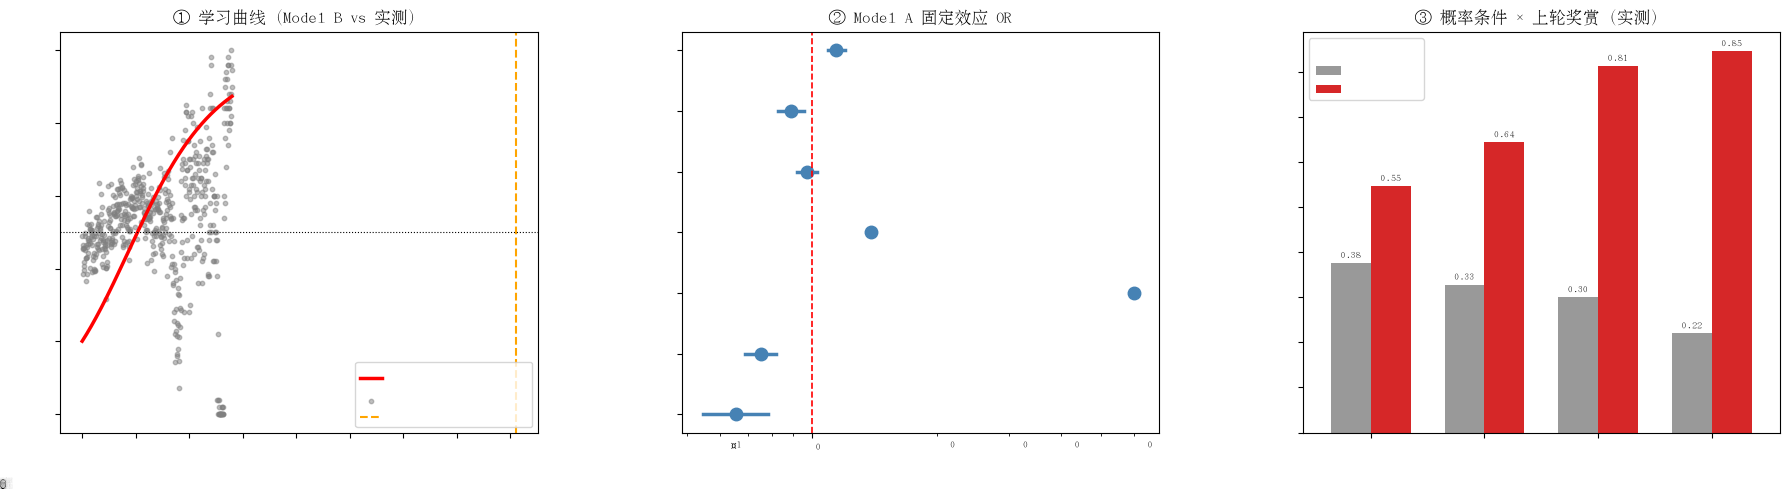

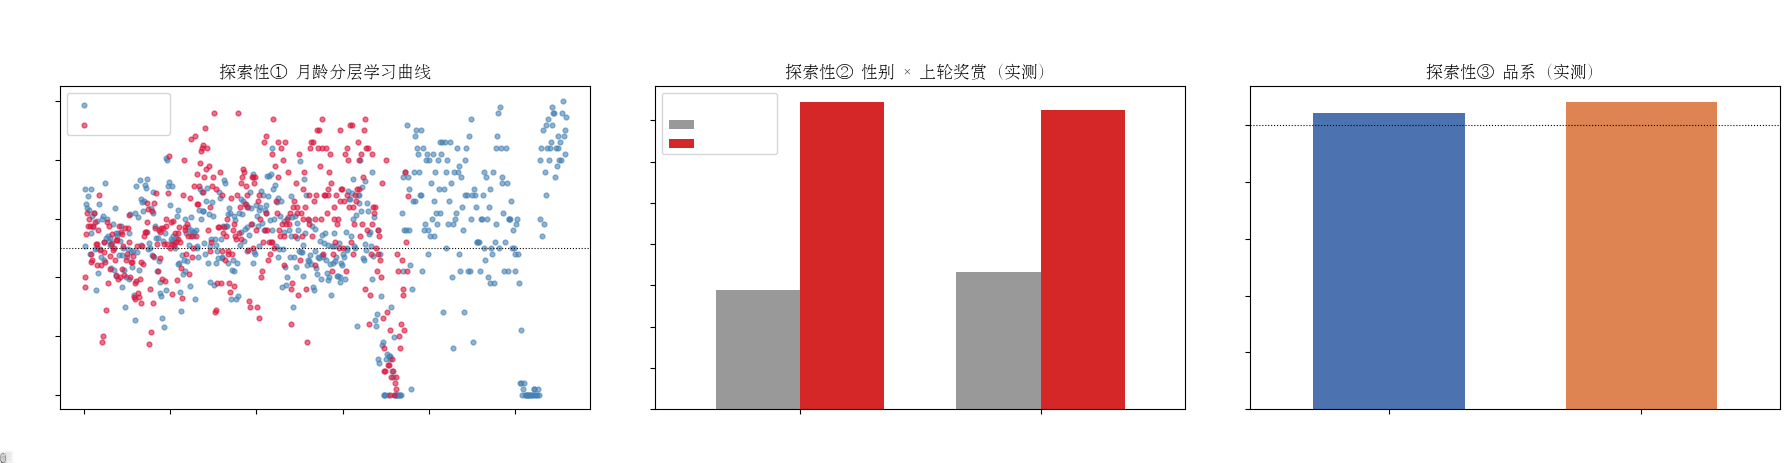

In [11]:
# GLME 可视化：学习曲线 + OR forest + 条件×上轮奖赏
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 中文字体（系统 AR PL UMing CN）
plt.rcParams['font.sans-serif'] = ['AR PL UMing CN']
plt.rcParams['axes.unicode_minus'] = False

GLME_DIR = "/home/jyy/Documents/Beh_Ana_J/glme"
# 跟随拟合格：有筛选子集则用子集，否则全量
FULL_CSV = f"{GLME_DIR}/glme_trial_data.csv"
SEL_CSV  = f"{GLME_DIR}/glme_trial_data_sel.csv"
USE_SEL = os.path.exists(SEL_CSV)
DATA_CSV = SEL_CSV if USE_SEL else FULL_CSV
RES_CSV  = f"{GLME_DIR}/glme_trial_data_sel.results.csv" if USE_SEL else f"{GLME_DIR}/glme_results.csv"
tag = "筛选子集" if USE_SEL else "全量"
res = pd.read_csv(RES_CSV)
dat = pd.read_csv(DATA_CSV)
print(f"可视化数据: {tag}")

# 三面板用【主分析】结果（全量剔Ac/Am）；按 analysis 过滤后再 set_index（否则 main/exp 同 term 冲突）
res_main = res[res["analysis"] == "main"]
mA = res_main[res_main["model"]=="A_Trial_linear"].set_index("term")
mB = res_main[res_main["model"]=="B_Trial_poly"].set_index("term")

# 主分析用到的数据行（剔Ac/Am，与 R 脚本一致）
import re
_pref = dat['Treatment'].apply(lambda t: re.match(r'^([A-Za-z]+?)\d[FW]$', t).group(1) if re.match(r'^([A-Za-z]+?)\d[FW]$', t) else None)
dat_main = dat[~_pref.isin(['Ac','Am'])].copy()

# 哪些固定效应在当前模型里（子集可能剔除单水平因子）
has_pc = any(t.startswith("ProbabilityCondition") for t in mA.index)
has_po = "PreviousOutcome1" in mA.index
has_re = "RestrictionW" in mA.index

fig, axes = plt.subplots(1, 3, figsize=(18,5))

# --- ① 学习曲线：Model B 预测 + 实测分箱 ---
ax = axes[0]
b0 = mB.loc["(Intercept)","beta"]
b1 = mB.loc["Trial_s","beta"]
b2 = mB.loc["I(Trial_s^2)","beta"]
trial = np.linspace(0, dat_main.Trial.max(), 500)
ts = trial/1000
logit = b0 + b1*ts + b2*ts**2
P = 1/(1+np.exp(-logit))
# 预测条件标签：有 ProbabilityCondition=7:3 ref，否则用唯一条件；有 PreviousOutcome=上轮无奖赏，否则基线
cond_lbl = "7:3" if has_pc else (dat_main['ProbabilityCondition'].iloc[0] if 'ProbabilityCondition' in dat_main else "")
po_lbl = "上轮无奖赏" if has_po else "基线(无上轮项)"
re_lbl = "限食F" if has_re else ""
ax.plot(trial, P, 'r-', lw=2.5, label=f'Model B 预测\n({cond_lbl}, {po_lbl}, {re_lbl})')
dat_main["_bin50"] = (dat_main.Trial-1)//50
agg = dat_main.groupby("_bin50").agg(tm=("Trial","mean"), rate=("ChoseHighProb","mean"), n=("ChoseHighProb","count"))
ax.scatter(agg.tm, agg.rate, s=10, c='gray', alpha=0.5, label='实测(每50trial)')
ts_sat = -b1/(2*b2)
ax.axvline(ts_sat*1000, color='orange', ls='--', lw=1.5, label=f'饱和点≈{ts_sat*1000:.0f} trial')
ax.axhline(0.5, color='k', ls=':', lw=0.8)
ax.set_xlabel("全局累计 Trial"); ax.set_ylabel("P(选高概率)")
ax.set_title("① 学习曲线（Model B vs 实测）"); ax.legend(fontsize=8, loc='lower right')

# --- ② OR forest plot (Model A)：只画存在的固定效应（含 Session_s + RestrictionW） ---
ax = axes[1]
all_terms = ["Trial_s","ProbabilityCondition6:4","ProbabilityCondition8:2","ProbabilityCondition9:1",
             "PreviousOutcome1","RestrictionW","Session_s"]
all_labels = ["Trial (每1000)","Prob 6:4 vs 7:3","Prob 8:2 vs 7:3","Prob 9:1 vs 7:3",
              "上轮奖赏","限水W vs 限食F","训练Session(每10)"]
present = [(t,l) for t,l in zip(all_terms, all_labels) if t in mA.index]
terms = [p[0] for p in present]
labels = [p[1] for p in present]
y = np.arange(len(terms))[::-1]
for i,t in enumerate(terms):
    r = mA.loc[t]
    ax.plot([r.OR_lo, r.OR_hi], [y[i],y[i]], color='steelblue', lw=2.5)
    ax.plot(r.OR, y[i], 'o', color='steelblue', ms=9)
    ax.text(r.OR_hi*1.02, y[i], f'{r.OR:.2f}', va='center', fontsize=8)
ax.axvline(1, color='r', ls='--', lw=1.2)
ax.set_yticks(y); ax.set_yticklabels(labels)
ax.set_xlabel("OR [95%CI]  (对数轴)"); ax.set_title("② Model A 固定效应 OR")
ax.set_xscale('log')

# --- ③ 条件 × 上轮奖赏 实测率（单水平条件/单水平上轮均兜底） ---
ax = axes[2]
grp_cols = [c for c in ["ProbabilityCondition","PreviousOutcome"] if c in dat_main.columns]
pivot = dat_main.groupby(grp_cols)["ChoseHighProb"].mean().unstack()
pivot.plot(kind='bar', ax=ax, color=['#999999','#d62728'], width=0.7)
ax.set_ylabel("选高概率率"); ax.set_title("③ 概率条件 × 上轮奖赏（实测）")
ax.set_xticklabels(pivot.index, rotation=0)
if pivot.shape[1] >= 2:
    ax.legend(['上轮无奖赏','上轮有奖赏'], fontsize=9, title='PreviousOutcome')
elif pivot.shape[1] == 1:
    ax.legend([f'PreviousOutcome={pivot.columns[0]}'], fontsize=9, title='PreviousOutcome')
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=7, padding=2)

plt.tight_layout()
plt.show()

# ====== 探索性附加：Age 学习曲线 + Sex×上轮奖赏 + Strain（complete-case 7鼠，不稳，仅参考） ======
res_exp = res[res["analysis"] == "exp"]
if not res_exp.empty:
    mAe = res_exp[res_exp["model"]=="A_Trial_linear"].set_index("term")
    mBe = res_exp[res_exp["model"]=="B_Trial_poly"].set_index("term")
    dat_exp = dat.dropna(subset=['Age','Sex']).copy()
    has_age = "Trial_s:Age" in mAe.index
    has_sex = "PreviousOutcome1:Sex1" in mAe.index
    has_strain = "StrainThy1" in mAe.index
    if has_age or has_sex or has_strain:
        fig2, axes2 = plt.subplots(1, 3, figsize=(18,4.5))
        # ① Age 学习曲线：按 Age 中位二分，画实测分箱
        if has_age and 'Age' in dat_exp.columns and dat_exp['Age'].nunique() > 1:
            ax = axes2[0]
            med = dat_exp['Age'].median()
            for sub, lbl, c in [(dat_exp['Age']<=med, f'低月龄≤{med:.0f}', 'steelblue'),
                                (dat_exp['Age']>med,  f'高月龄>{med:.0f}', 'crimson')]:
                dd = dat_exp[sub].copy()
                if len(dd)==0: continue
                dd["_b"] = (dd.Trial-1)//50
                ag = dd.groupby("_b").agg(tm=("Trial","mean"), rate=("ChoseHighProb","mean"))
                ax.scatter(ag.tm, ag.rate, s=12, c=c, alpha=0.6, label=lbl)
            ax.axhline(0.5, color='k', ls=':', lw=0.8)
            ax.set_xlabel("全局累计 Trial"); ax.set_ylabel("P(选高概率)")
            ax.set_title("探索性① 月龄分层学习曲线"); ax.legend(fontsize=9)
        else:
            axes2[0].axis('off')
        # ② Sex×上轮奖赏 实测率
        if has_sex and 'Sex' in dat_exp.columns:
            ax = axes2[1]
            sex_lbl = dat_exp['Sex'].map({0:'雌',1:'雄'}).fillna(dat_exp['Sex'].astype(str))
            dd = dat_exp.assign(SexLbl=sex_lbl)
            pv = dd.groupby(["SexLbl","PreviousOutcome"])["ChoseHighProb"].mean().unstack()
            pv.plot(kind='bar', ax=ax, color=['#999999','#d62728'], width=0.7)
            ax.set_ylabel("选高概率率"); ax.set_title("探索性② 性别 × 上轮奖赏（实测）")
            ax.set_xticklabels(pv.index, rotation=0)
            if pv.shape[1] >= 2:
                ax.legend(['上轮无奖赏','上轮有奖赏'], fontsize=9, title='PreviousOutcome')
            for c in ax.containers:
                ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
        else:
            axes2[1].axis('off')
        # ③ Strain WT vs Thy1 实测选高概率率
        if has_strain and 'Strain' in dat_exp.columns and dat_exp['Strain'].nunique() > 1:
            ax = axes2[2]
            pv = dat_exp.groupby("Strain")["ChoseHighProb"].agg(['mean','count'])
            pv['mean'].plot(kind='bar', ax=ax, color=['#4c72b0','#dd8452'], width=0.6)
            ax.axhline(0.5, color='k', ls=':', lw=0.8)
            ax.set_ylabel("选高概率率"); ax.set_title("探索性③ 品系（实测）")
            ax.set_xticklabels(pv.index, rotation=0)
            for c in ax.containers:
                ax.bar_label(c, fmt='%.2f', fontsize=9, padding=2)
            st = mAe.loc["StrainThy1"]
            ax.text(0.98, 0.02, f'StrainThy1 OR={st.OR:.2f}\np={st.p:.2g}', transform=ax.transAxes,
                    ha='right', va='bottom', fontsize=8, color='gray')
        else:
            axes2[2].axis('off')
        fig2.suptitle("探索性 · complete-case 7鼠（6雄1雌，Sex 不稳，仅参考）", y=1.02, fontsize=11, color='gray')
        plt.tight_layout()
        plt.show()

## 模型评估

评估 GLME 模型（Model A：`Trial_s + Session_s + ProbabilityCondition + PreviousOutcome + Restriction + (Trial_s|MouseID)`）的预测效果。

**8 面板可视化**：
1. **ROC 曲线** — AUC（区分度）
2. **校准曲线** — 预测概率 vs 实测概率（校准度）
3. **QQ 图** — 随机分位数残差（模拟 DHARMa 方法，适用于二项离散数据）
4. **Binned Residual** — 按预测概率分箱的 Pearson 残差均值
5. **混淆矩阵** — 分类准确率
6. **每鼠 AUC** — 各鼠模型区分度（含随机效应）
7. **Brier score 随 Trial** — 预测质量随试次变化
8. **每鼠预测 vs 实测** — 模型是否能区分不同鼠的水平差异

**核心指标**：AUC、准确率、Brier、LogLoss、McFadden 伪 R²、ICC、过度离散。


预测结果已存在，直接读取
评估数据: 全量  N=276,838 trials, 20 mice
  pred_fixed (边际): mean=0.5528  实测=0.5207
  pred_full  (含RE):  mean=0.5207

【模型评估核心指标】
  AUC (边际预测)          = 0.7291
  准确率 (阈值0.5)         = 0.6871
  Brier score             = 0.210800 (越小越好, <0.25 好)
  Log loss                = 0.613495
  McFadden 伪 R²          = 0.1138 (>0.2 优, 0.1-0.2 好)
  ICC (鼠内相关)          = 0.1474
  过度离散 (χ²/df)        = 4.822 ⚠
  空模型准确率            = 0.5207



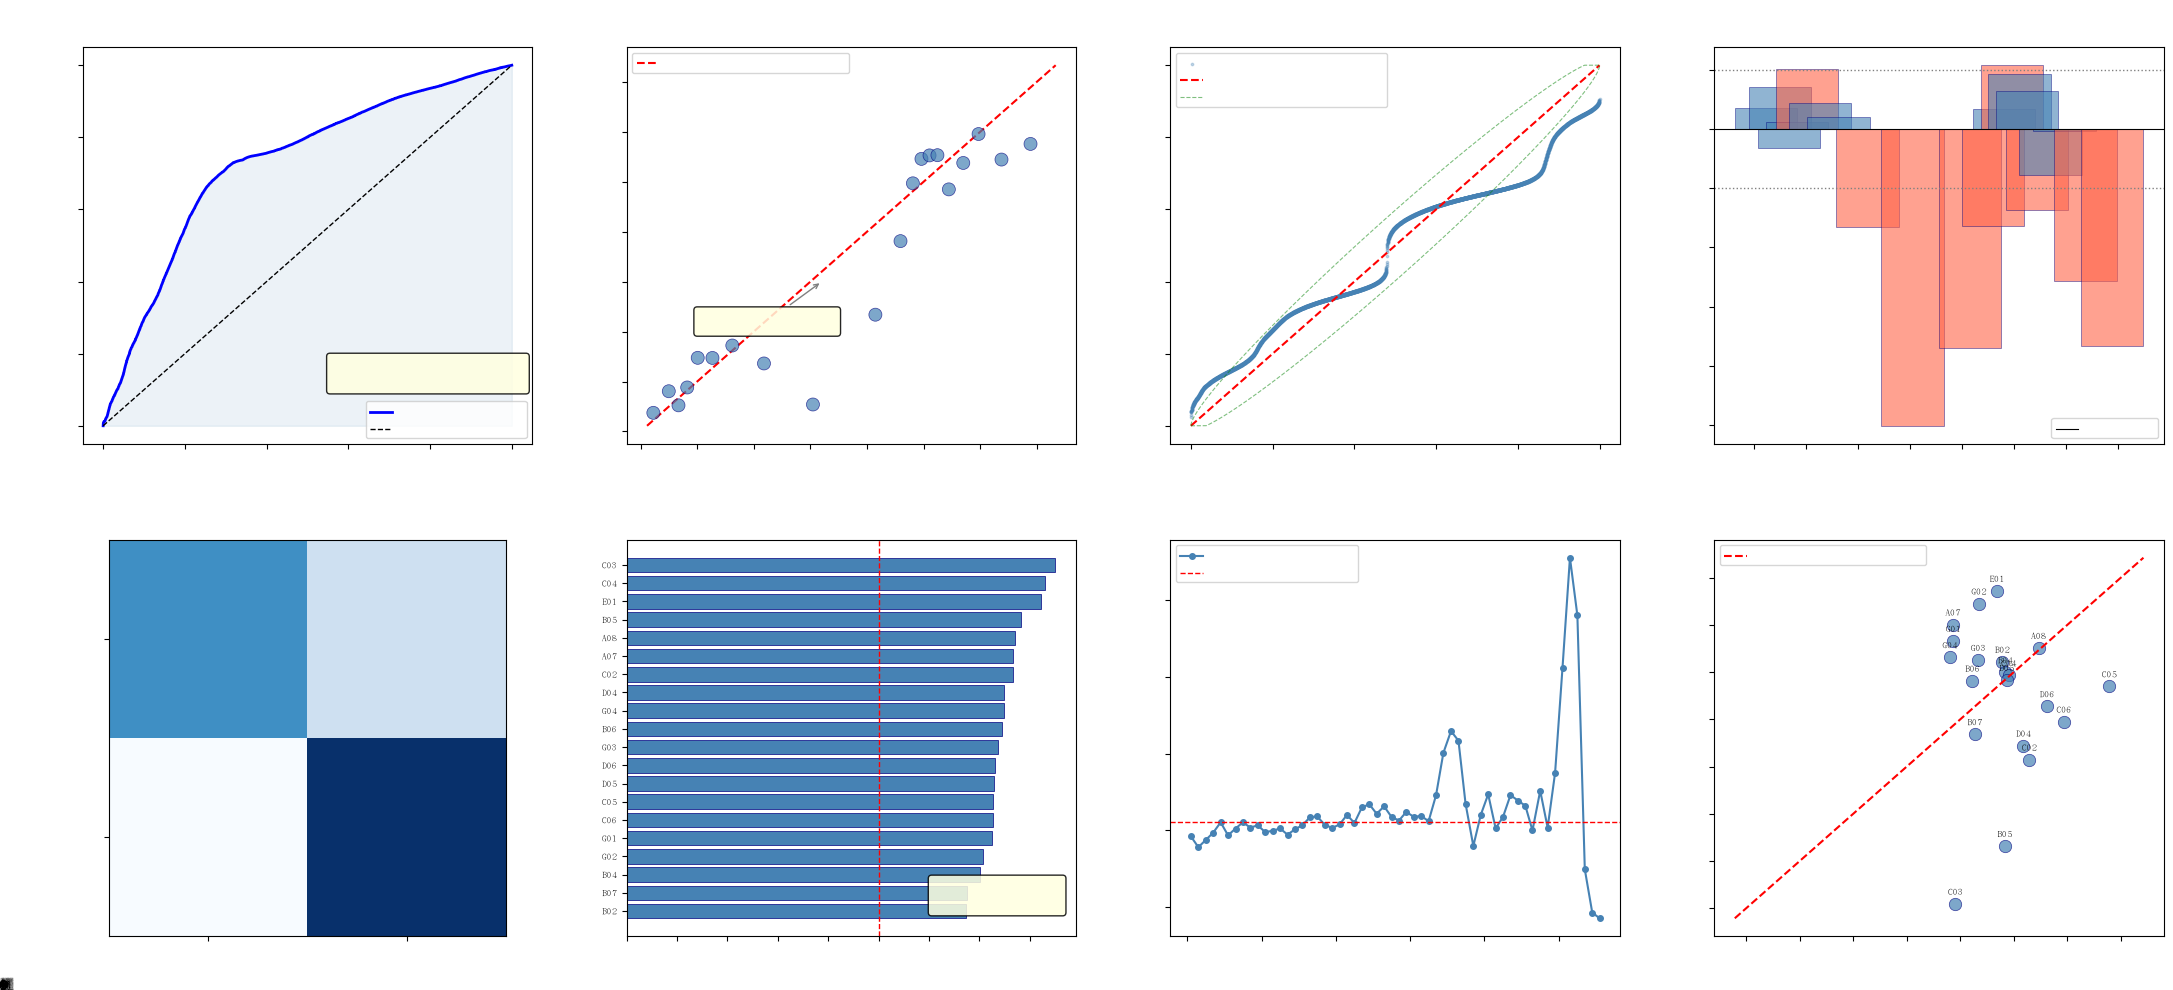


图已保存: /home/jyy/Documents/Beh_Ana_J/glme/eval_dashboard.png


In [12]:
# ============================================================
# GLME 模型评估 + 可视化：ROC/AUC、校准曲线、QQ图、binned residual、
# 混淆矩阵、Brier、LogLoss、每鼠准确率、伪R²、ICC
# ============================================================
import subprocess, os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, auc, roc_auc_score,
                             confusion_matrix, brier_score_loss, log_loss)

# 中文字体
plt.rcParams['font.sans-serif'] = ['AR PL UMing CN']
plt.rcParams['axes.unicode_minus'] = False

GLME_DIR  = "/home/jyy/Documents/Beh_Ana_J/glme"
FULL_CSV  = f"{GLME_DIR}/glme_trial_data.csv"
SEL_CSV   = f"{GLME_DIR}/glme_trial_data_sel.csv"
RSCRIPT   = "/opt/anaconda3/envs/glme/bin/Rscript"
EVAL_R    = f"{GLME_DIR}/eval_glme.R"

USE_SEL  = os.path.exists(SEL_CSV)
DATA_CSV = SEL_CSV if USE_SEL else FULL_CSV
PREDS_CSV = f"{GLME_DIR}/glme_eval_preds.csv"
MODEL_RDS = f"{GLME_DIR}/glme_eval_model.rds"
tag = "筛选子集" if USE_SEL else "全量"

# ---- 自动重算：预测文件/模型缺失或数据更新 ----
def _newer(a, b):
    return os.path.getmtime(a) > os.path.getmtime(b) if os.path.exists(a) and os.path.exists(b) else False

need_run = (not os.path.exists(PREDS_CSV)) or _newer(DATA_CSV, PREDS_CSV) or _newer(EVAL_R, PREDS_CSV)
if need_run:
    print(f"预测结果缺失/过期，调 Rscript 重拟合（约 2 分钟）…")
    env = dict(os.environ, GLME_DATA=DATA_CSV)
    r = subprocess.run([RSCRIPT, EVAL_R], capture_output=True, text=True, env=env)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr); raise RuntimeError("eval_glme.R 失败")
else:
    print("预测结果已存在，直接读取")

preds = pd.read_csv(PREDS_CSV)
y_true  = preds["y_true"].values
p_fixed = preds["pred_fixed"].values  # 边际预测（不含随机效应，评估用）
p_full  = preds["pred_full"].values   # 含随机效应（条件预测）
n_mice  = preds["MouseID"].nunique()
print(f"评估数据: {tag}  N={len(preds):,} trials, {n_mice} mice")
print(f"  pred_fixed (边际): mean={p_fixed.mean():.4f}  实测={y_true.mean():.4f}")
print(f"  pred_full  (含RE):  mean={p_full.mean():.4f}")
print()

# ============ 核心指标 ============
auc_val  = roc_auc_score(y_true, p_fixed)
acc_val  = ((p_fixed > 0.5) == y_true).mean()
brier    = brier_score_loss(y_true, p_fixed)
logloss  = log_loss(y_true, p_fixed)

# McFadden 伪 R²（基于边际预测）
eps = 1e-15
p_clip  = np.clip(p_fixed, eps, 1-eps)
ll_full = np.sum(y_true*np.log(p_clip) + (1-y_true)*np.log(1-p_clip))
null_rate = y_true.mean()
ll_null  = np.sum(y_true*np.log(null_rate) + (1-y_true)*np.log(1-null_rate))
mcfadden = 1 - ll_full/ll_null

# ICC（随机截距方差 / (随机截距方差 + π²/3)）
# 从拟合的 R 模型获取：用 Rscript 一步读
r_icc = subprocess.run([RSCRIPT, "-e",
    'suppressPackageStartupMessages(library(lme4)); '
    'm <- readRDS("' + MODEL_RDS + '"); '
    'vc <- VarCorr(m); '
    'var_int <- attr(vc$MouseID, "stddev")[1]^2; '
    'cat(var_int / (var_int + pi^2/3))'], capture_output=True, text=True)
try:
    icc = float(r_icc.stdout.strip())
except:
    icc = np.nan

# 过度离散（分组 Pearson χ²/df）
preds["_grp"] = preds["MouseID"].astype(str) + "|" + preds["Trial_s"].round(2).astype(str)
agg_d = preds.groupby("_grp").agg(n=("y_true","count"), y=("y_true","mean"), phat=("pred_fixed","mean"))
agg_d = agg_d[agg_d.n >= 5]  # 至少 5 条
pearson_chi2 = np.sum(agg_d.n * (agg_d.y - agg_d.phat)**2 / (agg_d.phat * (1-agg_d.phat)))
disp_df = len(agg_d) - 8  # 约减参数数
dispersion = pearson_chi2 / disp_df

print("="*60)
print("【模型评估核心指标】")
print("="*60)
print(f"  AUC (边际预测)          = {auc_val:.4f}")
print(f"  准确率 (阈值0.5)         = {acc_val:.4f}")
print(f"  Brier score             = {brier:.6f} (越小越好, <0.25 好)")
print(f"  Log loss                = {logloss:.6f}")
print(f"  McFadden 伪 R²          = {mcfadden:.4f} (>0.2 优, 0.1-0.2 好)")
print(f"  ICC (鼠内相关)          = {icc:.4f}" if not np.isnan(icc) else "  ICC                     = 读取失败")
print(f"  过度离散 (χ²/df)        = {dispersion:.3f} {'⚠' if dispersion > 1.5 else '✓'}")
print(f"  空模型准确率            = {max(null_rate, 1-null_rate):.4f}")
print()

# ============ 可视化：2×4 = 8 面板 ============
fig, axes = plt.subplots(2, 4, figsize=(22, 10))

# ---- ① ROC 曲线 ----
ax = axes[0][0]
fpr, tpr, _ = roc_curve(y_true, p_fixed)
ax.plot(fpr, tpr, 'b-', lw=2, label=f'模型曲线 (AUC={auc_val:.3f})')
ax.plot([0,1], [0,1], 'k--', lw=1, label='对角线=瞎猜 (AUC=0.5)')
ax.fill_between(fpr, tpr, alpha=0.1, color='steelblue')
ax.set_xlabel("假阳性率：预测'选高'但实际选低的比例", fontsize=10)
ax.set_ylabel("真阳性率：正确认出'选高'的比例", fontsize=10)
ax.set_title("① ROC 曲线：模型排序能力\n（蓝线下面积=AUC，越靠左上越好）", fontsize=11)
ax.legend(fontsize=8, loc='lower right')
ax.text(0.55, 0.22, f"蓝色阴影面积 = AUC = {auc_val:.3f}\n含义：随机抽两个试次，\n模型有 {auc_val:.0%} 概率把'更可能选高'的排对",
        fontsize=8, transform=ax.transAxes, va='top',
        bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.85))

# ---- ② 校准曲线 ----
ax = axes[0][1]
n_bins = 20
bin_edges = np.quantile(p_fixed, np.linspace(0, 1, n_bins+1))
bin_edges[0] -= 1e-10; bin_edges[-1] += 1e-10
bin_ids = np.digitize(p_fixed, bin_edges) - 1
cal_x, cal_y, cal_n = [], [], []
for b in range(n_bins):
    mask = bin_ids == b
    if mask.sum() > 10:
        cal_x.append(p_fixed[mask].mean())
        cal_y.append(y_true[mask].mean())
        cal_n.append(mask.sum())
ax.scatter(cal_x, cal_y, s=np.array(cal_n)/max(cal_n)*80+8, c='steelblue', alpha=0.7, edgecolors='navy', linewidth=0.5, zorder=5)
lims = [min(min(cal_x),min(cal_y))*0.95, max(max(cal_x),max(cal_y))*1.05]
ax.plot(lims, lims, 'r--', lw=1.5, label='红线=完美校准（点贴线=预测可信）')
ax.set_xlabel("模型预测概率（20个分位箱内的均值）", fontsize=10)
ax.set_ylabel("该箱实际选高概率", fontsize=10)
ax.set_title("② 校准曲线：预测概率可信吗\n（每个蓝点=一个箱，点越大=试次越多）", fontsize=11)
ax.legend(fontsize=8, loc='upper left')
ax.annotate("点贴红线 → 预测0.6的试次\n实际选高比例就是≈0.6", xy=(0.52, 0.5), xytext=(0.30, 0.40),
            fontsize=8, arrowprops=dict(arrowstyle='->', color='gray'),
            bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.85))

# ---- ③ QQ 图：随机分位数残差 ----
ax = axes[0][2]
# 生成随机分位数残差 (模拟 DHARMa)：对每个观测，从 U(0,p) 或 U(p,1) 采样
# y=1 → U(p, 1), y=0 → U(0, p)，模拟值从条件分布采样
np.random.seed(42)
n_sim = 100
sim_resid_all = np.zeros((len(preds), n_sim))
for s in range(n_sim):
    # 随机分位残差: (obs_cdf(y_obs) - U) 形式
    # proper approach: residual = P(Y_sim <= y_obs | p) - U * P(Y_sim = y_obs | p)
    # for binary: P(Y<=1)=1, P(Y=1)=p, P(Y<=0)=1-p, P(Y=0)=1-p
    resid = np.where(y_true==1, 1 - np.random.uniform(0, 1, len(preds)) * p_fixed,
                     (1 - p_fixed) - np.random.uniform(0, 1, len(preds)) * (1 - p_fixed))
    sim_resid_all[:, s] = resid
# 每行取模拟均值 → scaled residual
scaled_resid = sim_resid_all.mean(axis=1)
# QQ plot
sorted_r = np.sort(scaled_resid)
n = len(sorted_r)
theo_q = np.arange(1, n+1) / (n+1)
# 下采样画图（否则 276k 点太密）
step = max(1, n // 5000)
ax.scatter(theo_q[::step], sorted_r[::step], s=3, c='steelblue', alpha=0.3, label='蓝点=每个试次的残差（抽稀显示）')
ax.plot([0,1],[0,1],'r--',lw=1.5,label='红线=期望位置')
conf_band = 1.96 * np.sqrt(theo_q*(1-theo_q)/n_sim)
ax.plot(theo_q, np.clip(theo_q + conf_band, 0, 1), 'g--', lw=0.8, alpha=0.5)
ax.plot(theo_q, np.clip(theo_q - conf_band, 0, 1), 'g--', lw=0.8, alpha=0.5, label='绿虚线=95%置信带')
ax.set_xlabel("理论分位数（若模型正确应服从均匀分布）", fontsize=10)
ax.set_ylabel("模拟缩放残差（0~1）", fontsize=10)
ax.set_title("③ QQ 图：残差有无系统偏差\n（点贴红线且在绿带内=模型残差正常）", fontsize=11)
ax.legend(fontsize=8, loc='upper left')

# ---- ④ Binned residual（按预测值分箱） ----
ax = axes[0][3]
resid_pearson = (y_true - p_fixed) / np.sqrt(p_fixed * (1-p_fixed) + 1e-15)
n_bins_br = 20
bin_e = np.quantile(p_fixed, np.linspace(0, 1, n_bins_br+1))
bin_e[0] -= 1e-10; bin_e[-1] += 1e-10
bin_i = np.digitize(p_fixed, bin_e) - 1
br_mean, br_se, br_mid = [], [], []
for b in range(n_bins_br):
    mask = bin_i == b
    if mask.sum() > 5:
        br_mean.append(resid_pearson[mask].mean())
        br_se.append(2/np.sqrt(mask.sum()))
        br_mid.append(p_fixed[mask].mean())
br_mean, br_se, br_mid = np.array(br_mean), np.array(br_se), np.array(br_mid)
ax.bar(br_mid, br_mean, width=0.8/n_bins_br*3, alpha=0.6,
       color=['steelblue' if abs(m)<0.1 else 'tomato' for m in br_mean], edgecolor='navy', linewidth=0.5)
ax.axhline(0, color='k', lw=0.8, label='黑线0=无偏差')
ax.axhline(0.1, color='gray', ls=':', lw=1); ax.axhline(-0.1, color='gray', ls=':', lw=1)
ax.set_xlabel("模型预测概率（20个分位箱）", fontsize=10)
ax.set_ylabel("Pearson 残差均值（实测-预测，标准化）", fontsize=10)
ax.set_title("④ 分箱残差：各预测段偏差多大\n（柱高出±0.1灰线→红色=该段系统性偏差）", fontsize=11)
ax.legend(fontsize=8, loc='lower right')

# ---- ⑤ 混淆矩阵 ----
ax = axes[1][0]
y_pred_cls = (p_fixed > 0.5).astype(int)
cm = confusion_matrix(y_true, y_pred_cls)
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(['预测选低(0)','预测选高(1)'], fontsize=9)
ax.set_yticklabels(['实际选低(0)','实际选高(1)'], fontsize=9)
ax.set_xlabel("模型预测（阈值0.5：预测概率>0.5判'选高'）", fontsize=10)
ax.set_ylabel("实际选择", fontsize=10)
ax.set_title(f"⑤ 混淆矩阵：硬分类对错（准确率={acc_val:.1%}，\n瞎猜全选多数类={max(null_rate,1-null_rate):.1%}）", fontsize=11)
cell_note = [["判对√", "判错×"], ["判错 ×", "判对 √"]]
for i in range(2):
    for j in range(2):
        color = 'white' if cm[i,j] > cm.max()/2 else 'black'
        ax.text(j, i, f'{cm[i,j]:,}\n({cm[i,j]/cm.sum():.1%})\n{cell_note[i][j]}', ha='center', va='center', color=color, fontsize=9)

# ---- ⑥ 每鼠 AUC ----
ax = axes[1][1]
mouse_aucs = {}
for mid, grp in preds.groupby("MouseID"):
    if grp["y_true"].nunique() >= 2:
        mouse_aucs[mid] = roc_auc_score(grp["y_true"], grp["pred_full"])
if mouse_aucs:
    ma = pd.Series(mouse_aucs).sort_values()
    colors = ['tomato' if v < 0.5 else 'steelblue' for v in ma.values]
    ax.barh(range(len(ma)), ma.values, color=colors, edgecolor='navy', linewidth=0.5)
    ax.axvline(0.5, color='r', ls='--', lw=1)
    ax.set_yticks(range(len(ma))); ax.set_yticklabels(ma.index, fontsize=7)
    ax.set_xlabel("该鼠单独计算的 AUC（含随机效应预测）", fontsize=10)
    ax.set_ylabel("MouseID（按 AUC 从小到大排列）", fontsize=10)
    ax.set_title(f"⑥ 每鼠 AUC：模型对每只鼠管不管用\n（中位={ma.median():.3f}；红条<0.5=该鼠预测失效）", fontsize=11)
    ax.text(0.97, 0.06, "蓝条=AUC>0.5 模型有效\n红条=AUC<0.5 与瞎猜无异\n红虚线=0.5 瞎猜线", fontsize=8,
            transform=ax.transAxes, ha='right', va='bottom',
            bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.85))
else:
    ax.text(0.5, 0.5, "无数据", ha='center', va='center', transform=ax.transAxes)

# ---- ⑦ Brier 按试次（预测质量随 trial 变化） ----
ax = axes[1][2]
preds["_tb"] = (preds["Trial"]-1) // 500
tb = preds.groupby("_tb").apply(lambda g: pd.Series({
    "trial_mid": g["Trial"].mean(),
    "brier": ((g["pred_fixed"] - g["y_true"])**2).mean(),
    "n": len(g)}), include_groups=False).reset_index(drop=True)
ax.plot(tb.trial_mid, tb.brier, 'o-', color='steelblue', markersize=4, lw=1.5, label='蓝线=每500试次一段的Brier')
ax.axhline(brier, color='r', ls='--', lw=1, label=f'红虚线=总体 Brier={brier:.3f}')
ax.set_xlabel("全局累计试次 Trial（每500试次算一段）", fontsize=10)
ax.set_ylabel("Brier score（预测概率与结果的均方差，越小越准）", fontsize=10)
ax.set_title("⑦ Brier 随训练进程变化\n（曲线在线下=该段比总体更准；翘高=后期失准）", fontsize=11)
ax.legend(fontsize=8, loc='best')

# ---- ⑧ 预测 vs 实测 散点（按鼠聚合） ----
ax = axes[1][3]
mouse_agg = preds.groupby("MouseID").agg(pred=("pred_fixed","mean"), obs=("y_true","mean"))
ax.scatter(mouse_agg.pred, mouse_agg.obs, s=80, c='steelblue', alpha=0.7, edgecolors='navy', linewidth=0.5)
for mid, row in mouse_agg.iterrows():
    ax.annotate(mid, (row.pred, row.obs), fontsize=7, ha='center', va='bottom', xytext=(0,5), textcoords='offset points')
lims = [min(mouse_agg.pred.min(), mouse_agg.obs.min())*0.95, max(mouse_agg.pred.max(), mouse_agg.obs.max())*1.05]
ax.plot(lims, lims, 'r--', lw=1.5, label='红线=完美预测（点贴线=预测准）')
ax.set_xlabel("模型预测该鼠选高概率（边际，不含随机效应）", fontsize=10)
ax.set_ylabel("该鼠实际选高概率", fontsize=10)
ax.set_title("⑧ 每鼠预测 vs 实测：个体差异抓没抓住\n（每点=1只鼠，旁标MouseID）", fontsize=11)
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig(f"{GLME_DIR}/eval_dashboard.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"\n图已保存: {GLME_DIR}/eval_dashboard.png")


1、试次级学习存在。
2、跨训练日整体趋势下行——动机下降/疲劳/策略转换/后期任务变难
3、限水比限食少选高概率

Trial_s p=0.155 不显著了 OR 0.953。7 鼠试次级学习趋势检出力不够
StrainThy1 p=0.91 ns OR 1.027。WT vs Thy1 选高概率无差异（4WT/3Thy1，7鼠）。品系无影响
Trial_s:Age p=4e-8 显著 OR 1.016。月龄大学习更快（每+1月龄，1000 trial 学习效应 ×1.016）。交互显著但主效应 Age ns（p=0.38）
PreviousOutcome1:Sex1 p=3.9e-18 OR 1.397。雄鼠赢留更强。但 6 雄 1 雌，不稳，仅参考
Model B 二次项 p=0.91 ns，AIC B-A=+2.0 → 7 鼠非线性检验不出，Model A 够